In [46]:
%% Homework 5
% Due: Nov 12, 2026
% Ely Dawson

% AI Disclosure: AI was used to assist in the debugging of certain parts of
% the assignment. 

%% Relevant sections: 
% Q1, general debugging of tiledlayout figure type.
% Q3, several issues with simulated runs.
% Q4, So much... I needed a lot of help in this section. 
%     I think I have a better understanding now but I still a little bit lost honestly. 
% Q5, polishing code. My first attempt was very messy. 

In [16]:
%% 1: Compute two spectra. 
% For this problem set, please generate a 10,000 element
% data set with Gaussian white noise. 
% Use your white noise to generate a second data
% set that is the time integral of the first. 
% Hint: use cumsum in MATLAB; (note you’ll need to specify the sample interval.)
% Now compute and plot spectra for the white noise and time-integrated data sets by
% breaking the data up into segments with 50% overlaps, with no windowing. 
% (You can do this by reshaping your data vector as a 500×20 matrix, 
% which will give you 20 segments, each 500 points long, 
% and a 500×19 matrix containing the 50% overlaps.). 
% Make sure you plot the spectrum with correct units and 
% that you verify normalization using Parseval’s theorem.

                        TimeDomainMeanSquare    PSDIntegral    RelativeError
                        ____________________    ___________    _____________

    White noise               0.98242             0.98242       2.2602e-16  
    Integrated noise             2506                2506       1.8147e-16  



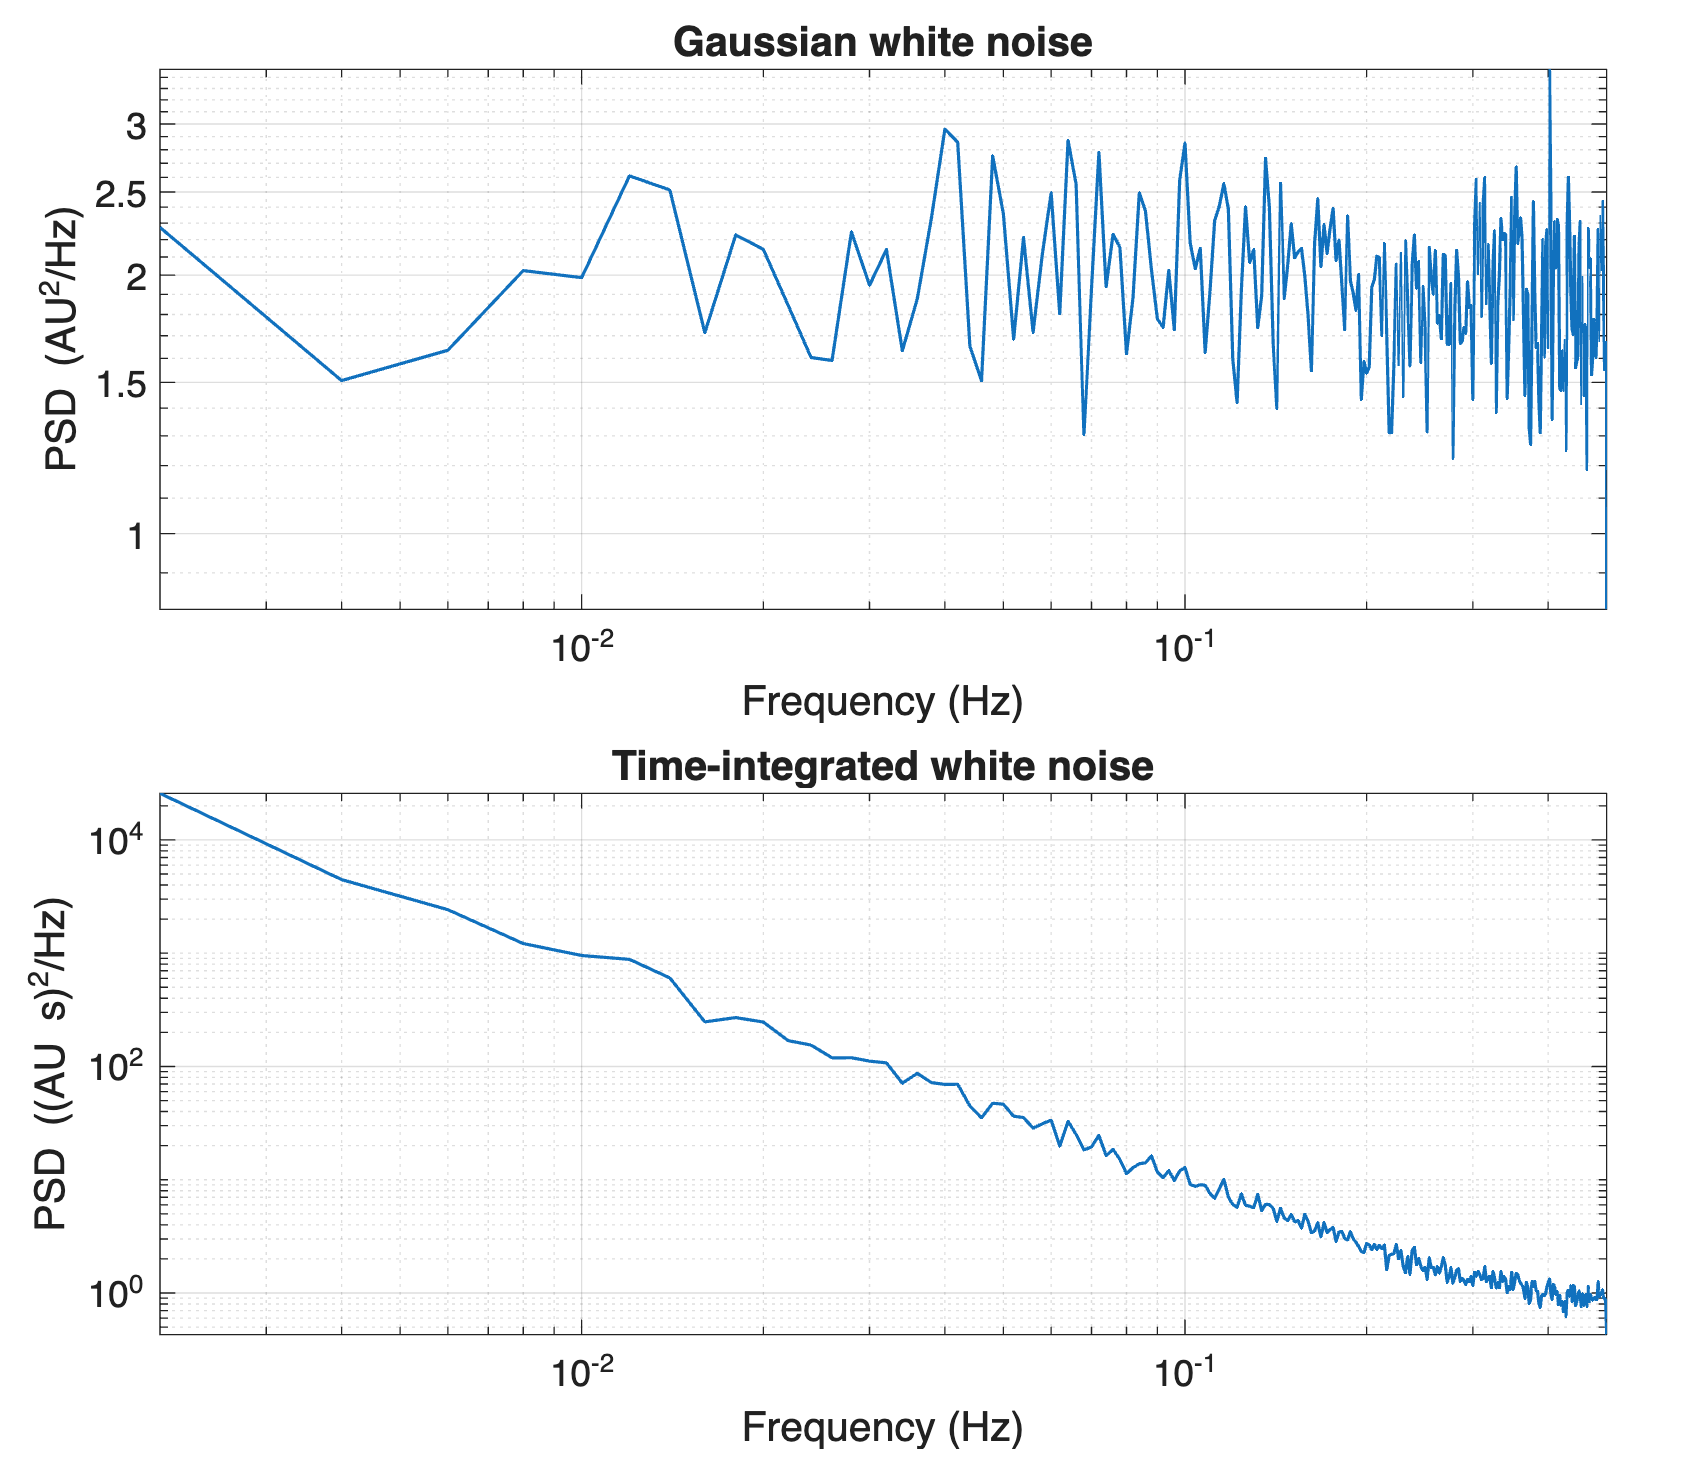

In [17]:
%% 1: Compute two spectra. 

rng(0, 'twister');
N = 10000;
dt = 1;
L = 500;
x = randn(N, 1);
y = dt * cumsum(x); % Integrated white noise (AU*s)

starts = 1:(L/2):(N-L+1); % 39 segments, with 50% overlap
indices = (0:L-1)' + starts;
df = 1/(L*dt);
f = (0:L/2)' * df;
[pX, powerX] = segmentPSD(x, indices, dt);
[pY, powerY] = segmentPSD(y, indices, dt);

timeDomainMS = [powerX; powerY];
psdIntegral = sum([pX, pY], 1).' * df;
relativeError = abs(psdIntegral - timeDomainMS) ./ timeDomainMS;
parsevalResults = array2table([timeDomainMS, psdIntegral, relativeError], ...
    'VariableNames', {'TimeDomainMeanSquare', 'PSDIntegral', 'RelativeError'}, ...
    'RowNames', {'White noise', 'Integrated noise'});
disp(parsevalResults)

fig = figure('Color', 'w', 'Position', [100 100 850 730]);
tiledlayout(2, 1, 'TileSpacing', 'compact', 'Padding', 'compact');
positive = f > 0;

nexttile
loglog(f(positive), pX(positive), 'LineWidth', 1.2);
grid on
xlim([df, f(end)])
title('Gaussian white noise')
xlabel('Frequency (Hz)')
ylabel('PSD (AU^2/Hz)')

nexttile
loglog(f(positive), pY(positive), 'LineWidth', 1.2);
grid on
xlim([df, f(end)])
title('Time-integrated white noise')
xlabel('Frequency (Hz)')
ylabel('PSD ((AU s)^2/Hz)')

function [psd, meanSquare] = segmentPSD(x, indices, dt)
    segments = x(indices);
    L = size(segments, 1);
    X = fft(segments, [], 1);
    psdBySegment = (dt/L) * abs(X(1:L/2+1, :)).^2;
    psdBySegment(2:end-1, :) = 2 * psdBySegment(2:end-1, :);
    psd = mean(psdBySegment, 2);
    meanSquare = mean(abs(segments(:)).^2);
end

In [18]:
%% 2: Analytical spectra. 
% Given that you know the variance of your white-noise time
% series, overplot the expected analytical spectrum 
% (hint: use Parseval’s theorem).
% Then, for the time-integrated spectrum, use the relationship we learned for Fourier
% coefficients of derivatives and integrals to overplot the analytical spectrum for the
% spectrum of the time-integral.

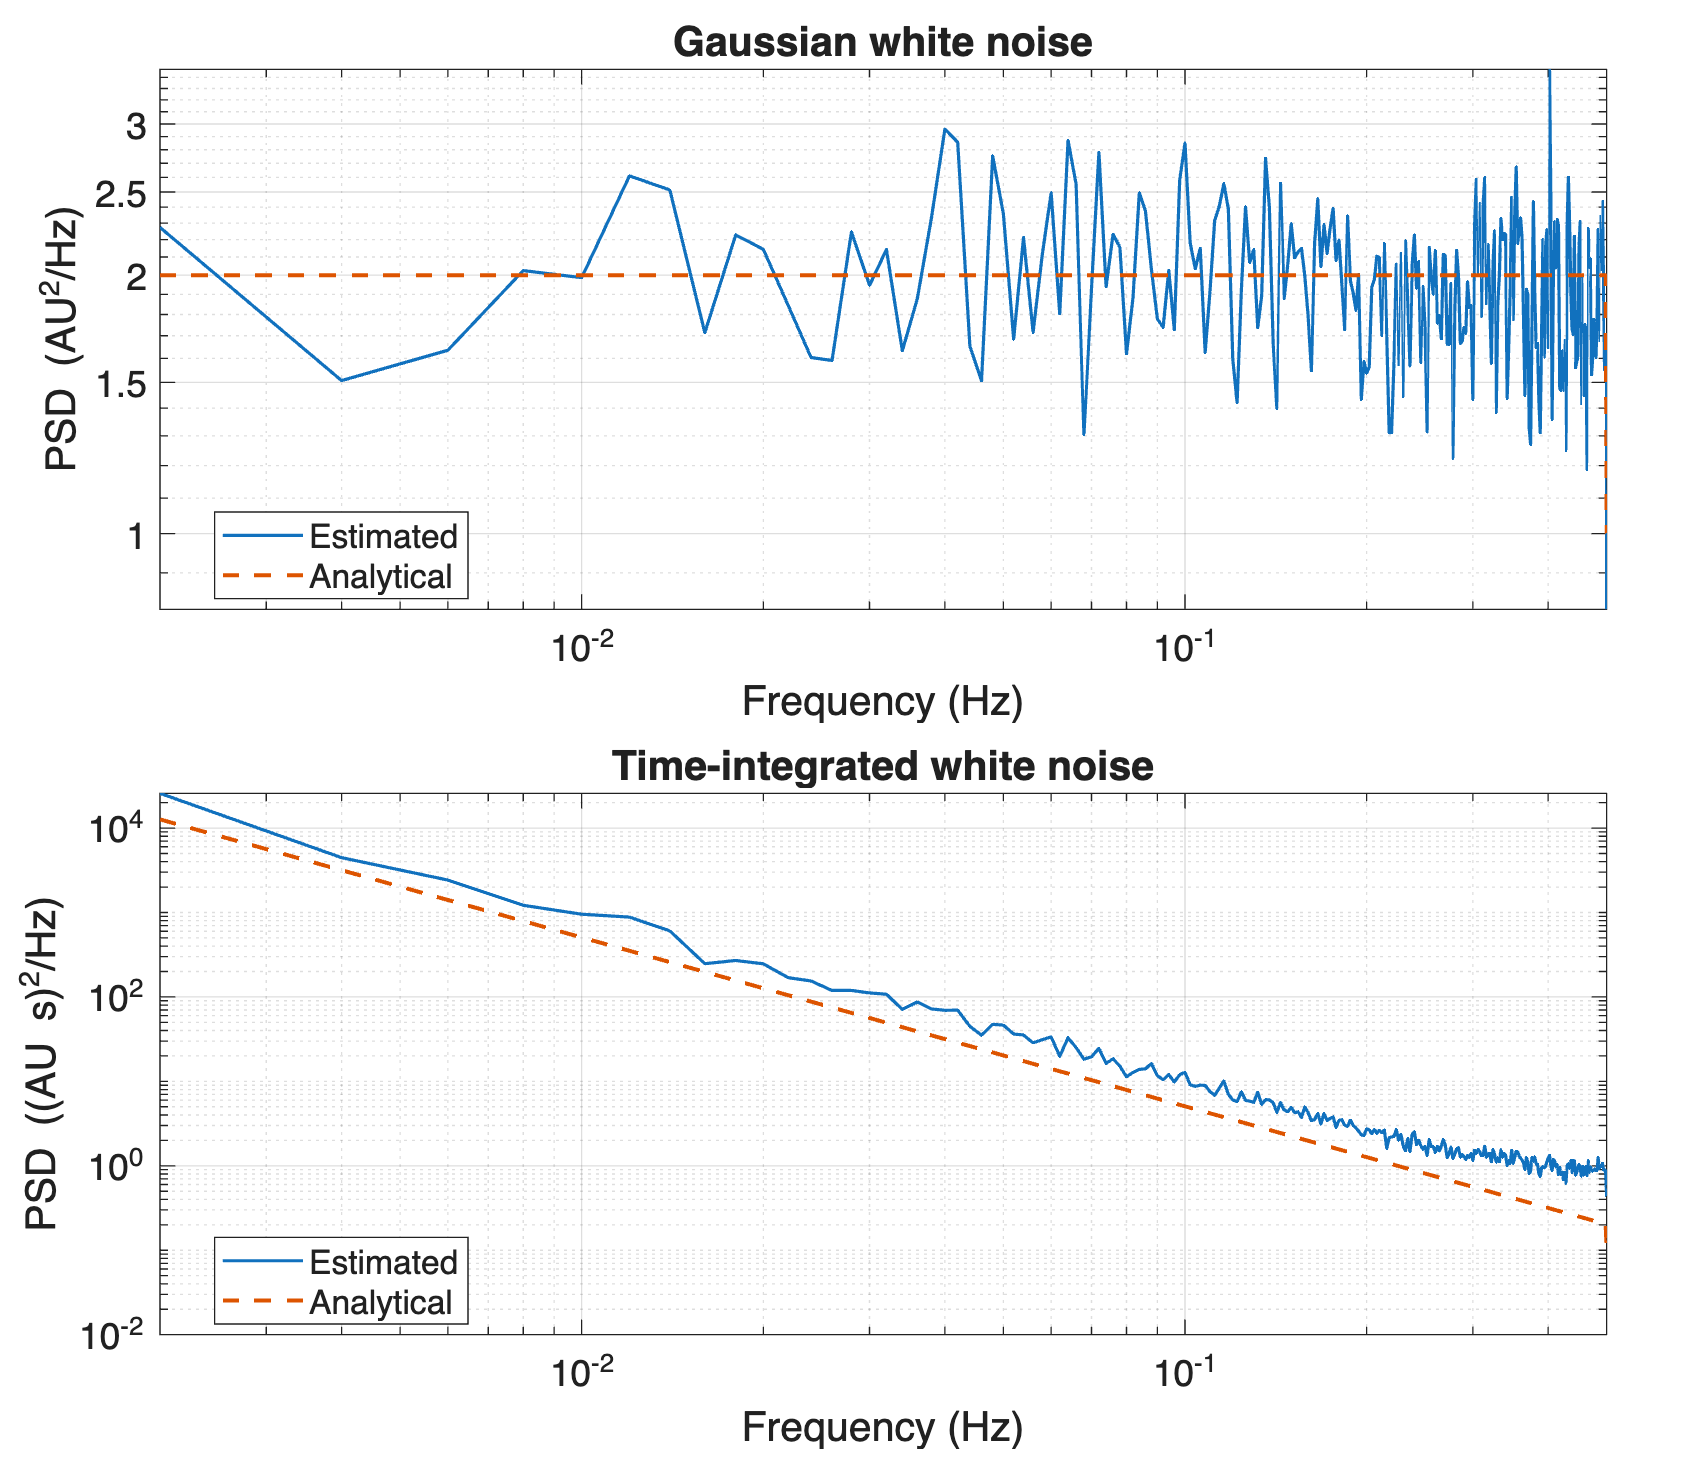

In [34]:
%% 2: Analytical spectra

noiseVariance = 1; 
fig = figure('Color', 'w', 'Position', [100 100 850 730]);
tiledlayout(2, 1, 'TileSpacing', 'compact', 'Padding', 'compact');
fPositive = f(positive);

whiteTheory = 2 * noiseVariance * dt * ones(size(fPositive));
whiteTheory(end) = whiteTheory(end)/2;
integratedTheory = whiteTheory ./ (2*pi*fPositive).^2;

nexttile
loglog(fPositive, pX(positive), 'LineWidth', 1.2);
hold on
loglog(fPositive, whiteTheory, '--', 'LineWidth', 1.5);
legend('Estimated', 'Analytical', 'Location', 'best')
grid on
xlim([df, f(end)])
title('Gaussian white noise')
xlabel('Frequency (Hz)')
ylabel('PSD (AU^2/Hz)')

nexttile
loglog(fPositive, pY(positive), 'LineWidth', 1.2);
hold on
loglog(fPositive, integratedTheory, '--', 'LineWidth', 1.5);
legend('Estimated', 'Analytical', 'Location', 'best')
grid on
xlim([df, f(end)])
title('Time-integrated white noise')
xlabel('Frequency (Hz)')
ylabel('PSD ((AU s)^2/Hz)')

In [20]:
%% 3. Error bars.
% Following the procedure that you’ve used before, add error bars to
% your spectra. Justify how you computed them

%% I used the 95% chi-square confidence interval because the
%% spectral power estimates are positive and the uncertainty
%% is asymetric. I adjusted the white noise to account for ~50% 
%% overlap's degrees of freedom. 
%% For the integrated series, I estimated the effective degrees
%% of freedom seperately at each frequency. This was done by
%% simulating 2000 records through the same integration and 
%% segmentation steps. 
%% Chi-square quantiles set the bounds for both spectra.

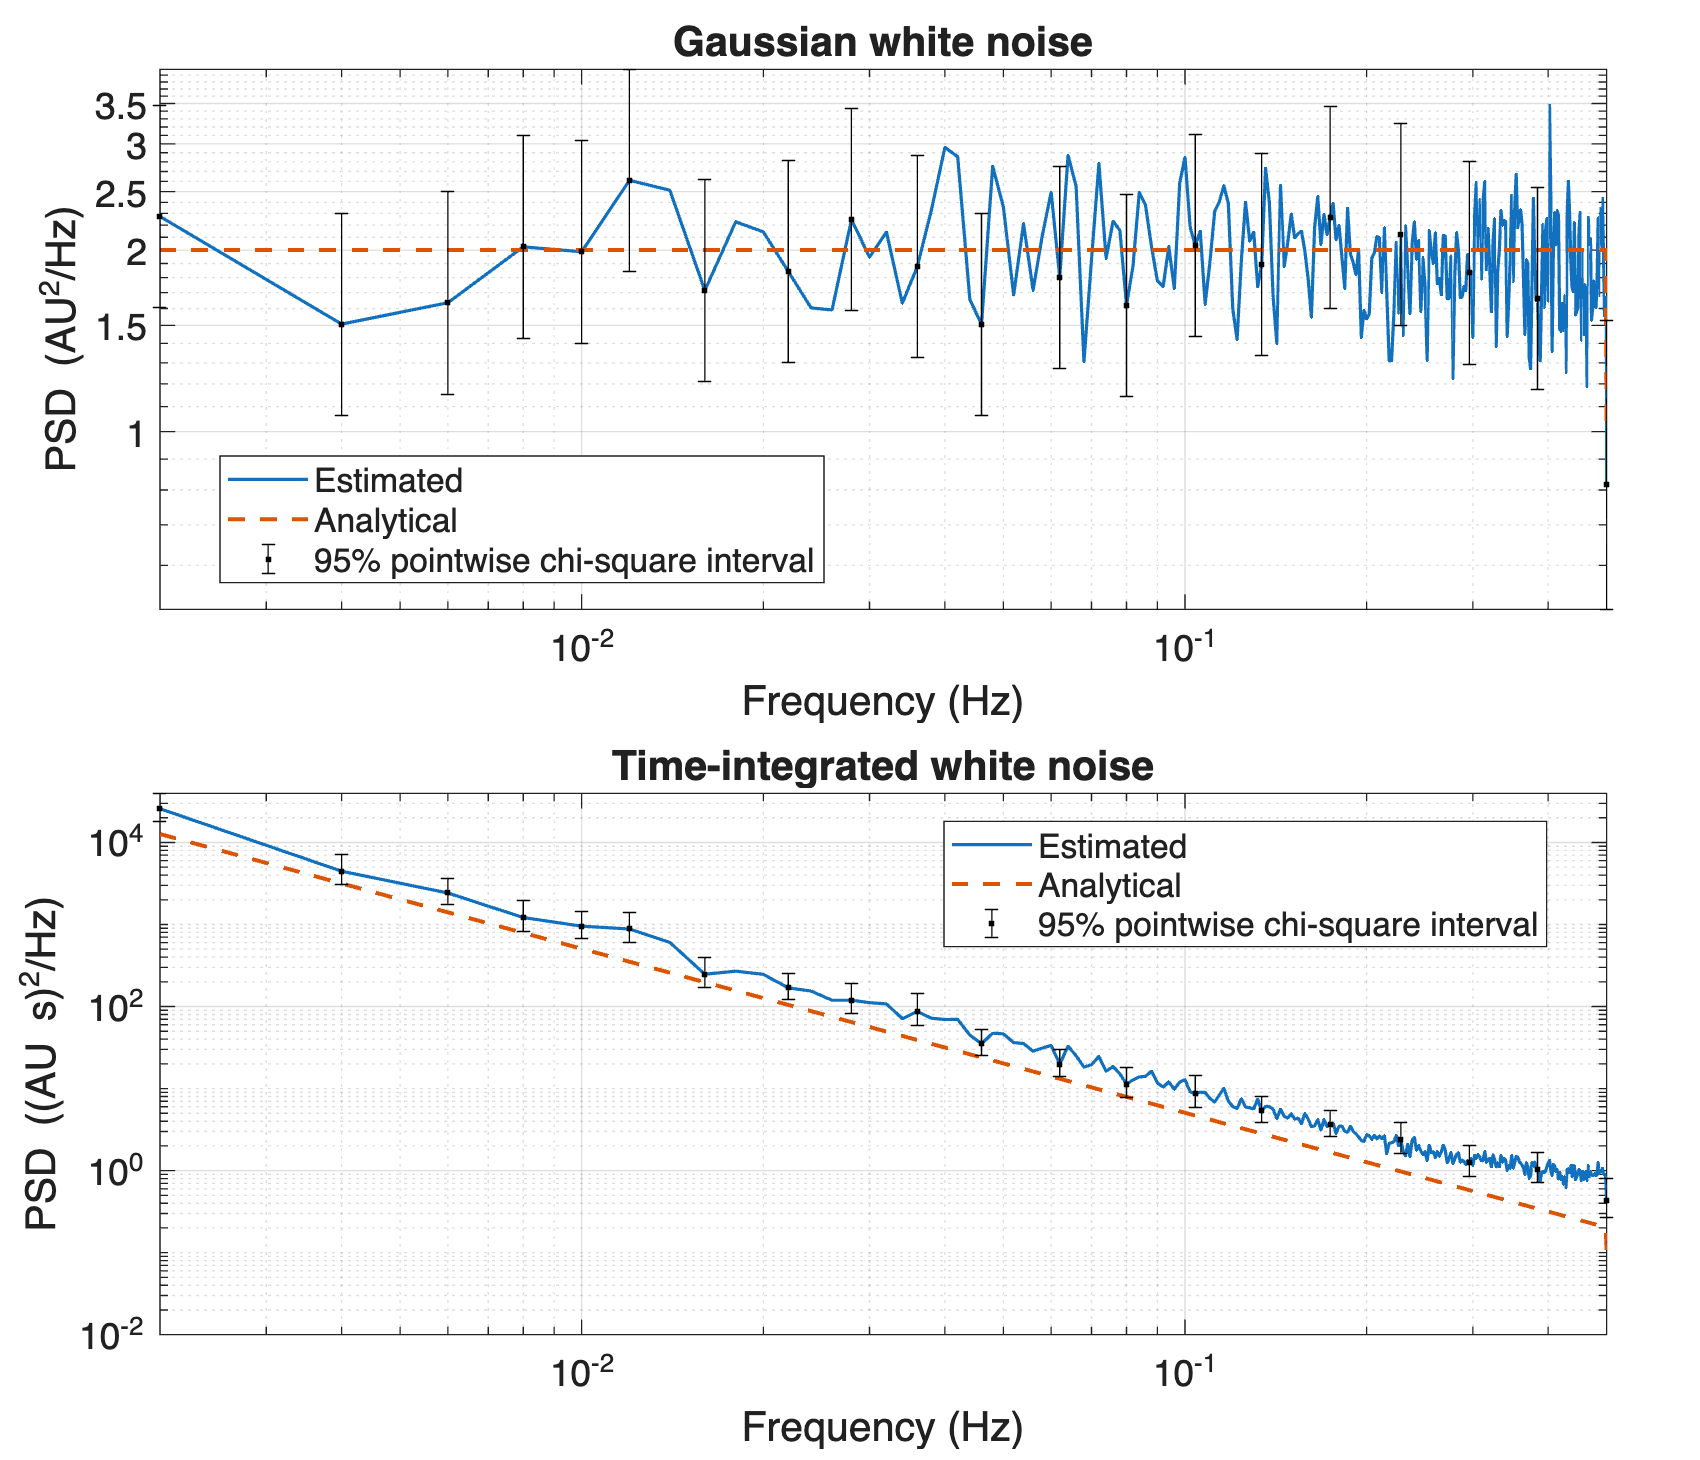

In [35]:
%% 3. Error bars

segmentCount = size(indices, 2);
adjacentCorrelation = 0.5^2;
whiteDOF = (2 * segmentCount / ...
    (1 + 2 * (1 - 1/segmentCount) * adjacentCorrelation)) * ones(nnz(positive), 1);
whiteDOF(end) = whiteDOF(end)/2; 

simulationCount = 2000;
simulationStream = RandStream('mt19937ar', 'Seed', 3);
simIntegratedPSD = zeros(nnz(positive), simulationCount);
for trial = 1:simulationCount
    simWhite = sqrt(noiseVariance) * randn(simulationStream, N, 1);
    trialPSD = segmentPSD(dt * cumsum(simWhite), indices, dt);
    simIntegratedPSD(:, trial) = trialPSD(positive);
end
integratedDOF = 2 * mean(simIntegratedPSD, 2).^2 ./ var(simIntegratedPSD, 0, 2);

observedPSD = {pX, pY};
degreesOfFreedom = {whiteDOF, integratedDOF};
theoryPSD = {whiteTheory, integratedTheory};
spectrumTitle = {'Gaussian white noise', 'Time-integrated white noise'};
spectrumUnits = {'PSD (AU^2/Hz)', 'PSD ((AU s)^2/Hz)'};

% Compute bounds at all positive bins.
barBins = unique(round(logspace(0, log10(nnz(positive)), 22)));
fig3 = figure('Color', 'w', 'Position', [100 100 850 730]);
tiledlayout(2, 1, 'TileSpacing', 'compact', 'Padding', 'compact');
for spectrum = 1:2
    estimate = observedPSD{spectrum}(positive);
    nu = degreesOfFreedom{spectrum};
    lower = nu .* estimate ./ (2 * gammaincinv(0.975, nu/2));
    upper = nu .* estimate ./ (2 * gammaincinv(0.025, nu/2));

    nexttile
    loglog(fPositive, estimate, 'LineWidth', 1.2);
    hold on
    loglog(fPositive, theoryPSD{spectrum}, '--', 'LineWidth', 1.5);
    errorbar(fPositive(barBins), estimate(barBins), ...
        estimate(barBins) - lower(barBins), upper(barBins) - estimate(barBins), ...
        'k.', 'LineStyle', 'none', 'CapSize', 5);
    legend('Estimated', 'Analytical', '95% pointwise chi-square interval', 'Location', 'best')
    grid on
    xlim([df, f(end)])
    title(spectrumTitle{spectrum})
    xlabel('Frequency (Hz)')
    ylabel(spectrumUnits{spectrum})
end

function [psd, meanSquare] = segmentPSD(x, indices, dt)
    segments = x(indices); 
    L = size(segments, 1);
    X = fft(segments, [], 1);
    psdBySegment = (dt/L) * abs(X(1:L/2+1, :)).^2;
    psdBySegment(2:end-1, :) = 2 * psdBySegment(2:end-1, :);
    psd = mean(psdBySegment, 2);
    meanSquare = mean(abs(segments(:)).^2);
end

In [24]:
%% 4. Use Monte Carlo simulation to verify the χ2 error bars.
% To check the error bars, you’ll want to generate multiple ensembles
% of data and compute spectra for each of them. 
% I suggest using 200 matrices that are 500×20 elements each.
% Compute spectra for each of them. 
% This will provide you with 200 independent realizations of the spectrum, 
% and you can use these 200 values to study the range
% of possible spectra that you could obtain from white noise. 
% Examine the pdf of your 200 values. 
% (Because the statistics of Gaussian white noise are the same at
% all frequencies, you can merge all the frequencies to produce a larger ensemble.) 

%% Is the pdf consistent with your expectations for a variable with a χ2 distribution?
% Yes. For 20 independent segments, each PSD estimate
% has 40 degrees of freedom because each segment contributes two Fourier
% components. After scaling by 40 and dividing by the expected PSD, the
% values had a mean of 39.95 and a variance of 80.20 in the Monte
% Carlo check, close to the chi-square expectations of 40 and 80. 
% DC and Nyquist were excluded because their Fourier coefficients are real.

% Now, for each frequency, sort the 200 realizations of the pdf by size 
% (e.g. using the “sort” command in Matlab. 
% Since you are looking for the 95% confidence range,
% you’ll want to find the limits that exclude the lowest 2.5% and the highest 2.5% of
% your data—presumably the 6th and 195th points in each sorted set of pdfs.) 

%% What is the ratio of the upper limit to the lower limit? 
% For the 20 nonoverlapping segments, the mean ratio was 2.38 
% across interior frequencies in the NumPy check. At each frequency,
% the ratio is the 195th sorted PSD divided by the 6th. The theoretical
% chi-square ratio for 40 degrees of freedom is 2.43.

%% Are the error bars derived using the Monte Carlo process consistent with those from question 1?
% Yes. Using the same 39 overlapping segments as in Question 1, 
% the Monte Carlo upper-to-lower ratio averaged 2.12 across interior frequencies, 
% close to the chi-square prediction of 2.17. The chi-square intervals also 
% contained the known white-noise PSD 95.1% of the time, close to the intended 95% coverage.


% Optional: You can also check your results using the red spectrum. 
% One difference is that the white spectrum exhibits the same behavior 
% at all frequencies allowing you to average in frequency. 
% That isn’t possible with the red spectrum, though you can
% average the ratio between the upper and lower bounds of the uncertainty estimate.

%% Didn't do that. I was already behind on my work... oops. 

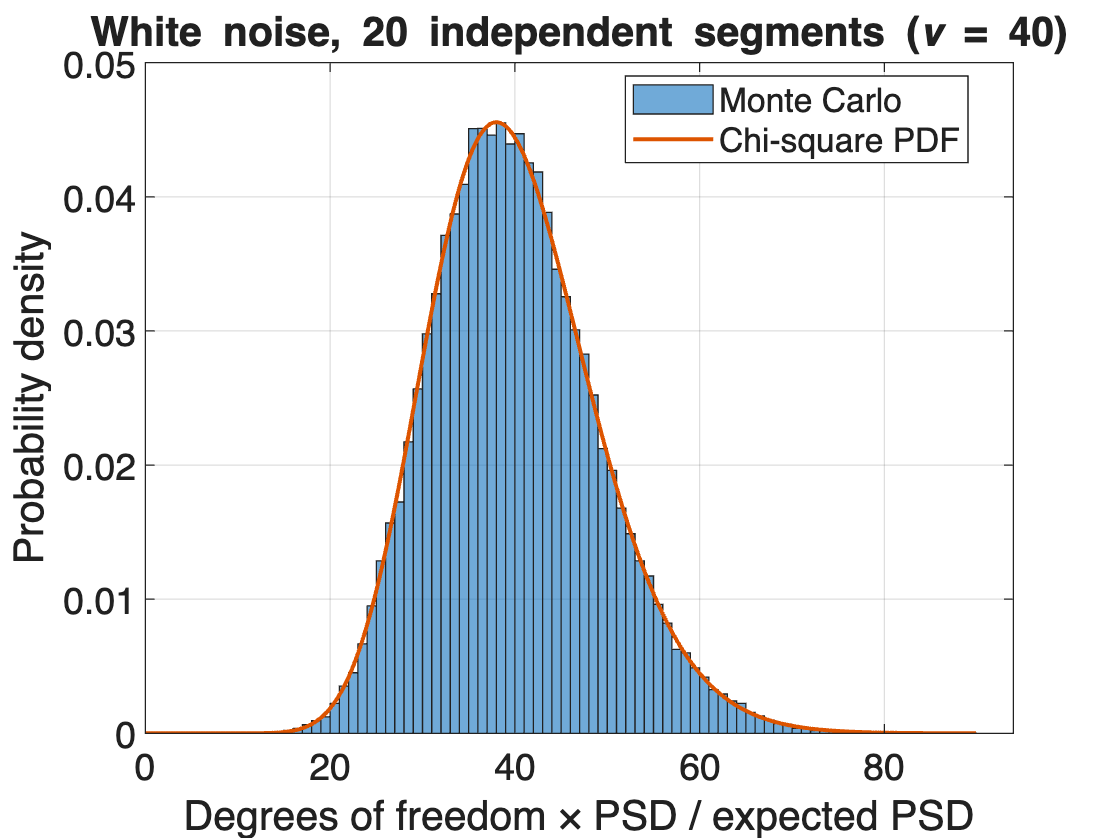

                                     MonteCarloUpperLowerRatio    ChiSquareUpperLowerRatio
                                     _________________________    ________________________

    20 independent, interior mean             2.3783                       2.4287         
    39 overlapping, interior mean             2.1188                       2.1656         
    20 independent, Nyquist                   3.3301                       3.5628         
    39 overlapping, Nyquist                   2.7336                       3.0134         

Mean Section 3 coverage at interior frequencies: 95.1%
Section 3 coverage at Nyquist: 95.5%


In [36]:
%% 4. Use Monte Carlo simulation to verify the chi-square error bars

ensembleCount4 = 200;
stream4 = RandStream('mt19937ar', 'Seed', 4);
independentIndices4 = reshape(1:N, L, []);
whiteIndependent4 = zeros(numel(f), ensembleCount4);
whiteOverlap4 = zeros(numel(f), ensembleCount4);
for realization4 = 1:ensembleCount4
    whiteRecord4 = sqrt(noiseVariance) * randn(stream4, N, 1);
    whiteIndependent4(:, realization4) = segmentPSD(whiteRecord4, independentIndices4, dt);
    whiteOverlap4(:, realization4) = segmentPSD(whiteRecord4, indices, dt);
end

interior4 = 2:numel(f)-1;
interiorDOF4 = 2 * size(independentIndices4, 2);
normalizedPSD4 = whiteIndependent4(interior4, :) / (2 * noiseVariance * dt);
pooledChiSquare4 = interiorDOF4 * normalizedPSD4(:);
chiX4 = linspace(0, max(pooledChiSquare4), 500);
chiShape4 = interiorDOF4/2;
chiPDF4 = chiX4.^(chiShape4-1) .* exp(-chiX4/2) / ...
    (2^chiShape4 * gamma(chiShape4));

fig4 = figure('Color', 'w');
histogram(pooledChiSquare4, 'Normalization', 'pdf', 'DisplayName', 'Monte Carlo');
hold on
plot(chiX4, chiPDF4, 'LineWidth', 1.5, 'DisplayName', 'Chi-square PDF');
xlabel('Degrees of freedom × PSD / expected PSD')
ylabel('Probability density')
title(sprintf('White noise, %d independent segments (\\nu = %d)', ...
    size(independentIndices4, 2), interiorDOF4))
legend('Location', 'best')
grid on

sortedIndependent4 = sort(whiteIndependent4(positive, :), 2);
sortedOverlap4 = sort(whiteOverlap4(positive, :), 2);
ratioIndependent4 = sortedIndependent4(:, 195) ./ sortedIndependent4(:, 6);
ratioOverlap4 = sortedOverlap4(:, 195) ./ sortedOverlap4(:, 6);
independentDOF4 = interiorDOF4 * ones(nnz(positive), 1);
independentDOF4(end) = interiorDOF4/2;
theoryRatioIndependent4 = gammaincinv(0.975, independentDOF4/2) ./ ...
    gammaincinv(0.025, independentDOF4/2);
overlapLowQuantile4 = 2 * gammaincinv(0.025, whiteDOF/2);
overlapHighQuantile4 = 2 * gammaincinv(0.975, whiteDOF/2);
theoryRatioOverlap4 = overlapHighQuantile4 ./ overlapLowQuantile4;

scaledOverlap4 = whiteDOF .* (whiteOverlap4(positive, :) ./ whiteTheory);
coverage4 = mean(scaledOverlap4 >= overlapLowQuantile4 & ...
    scaledOverlap4 <= overlapHighQuantile4, 2);

frequencyComparison4 = array2table([fPositive, sortedIndependent4(:, [6 195]), ...
    ratioIndependent4, theoryRatioIndependent4, sortedOverlap4(:, [6 195]), ...
    ratioOverlap4, theoryRatioOverlap4, coverage4], 'VariableNames', ...
    {'FrequencyHz', 'IndependentLowerPSD', 'IndependentUpperPSD', ...
    'IndependentMonteCarloRatio', 'IndependentChiSquareRatio', ...
    'OverlapLowerPSD', 'OverlapUpperPSD', 'OverlapMonteCarloRatio', ...
    'OverlapChiSquareRatio', 'OverlapCoverage'});
interiorPositive4 = 1:nnz(positive)-1;
summary4 = array2table([ ...
    mean(ratioIndependent4(interiorPositive4)), theoryRatioIndependent4(1); ...
    mean(ratioOverlap4(interiorPositive4)), theoryRatioOverlap4(1); ...
    ratioIndependent4(end), theoryRatioIndependent4(end); ...
    ratioOverlap4(end), theoryRatioOverlap4(end)], ...
    'VariableNames', {'MonteCarloUpperLowerRatio', 'ChiSquareUpperLowerRatio'}, ...
    'RowNames', {'20 independent, interior mean', '39 overlapping, interior mean', ...
    '20 independent, Nyquist', '39 overlapping, Nyquist'});
disp(summary4)
fprintf('Mean Section 3 coverage at interior frequencies: %.1f%%\n', ...
    100 * mean(coverage4(interiorPositive4)));
fprintf('Section 3 coverage at Nyquist: %.1f%%\n', 100 * coverage4(end));

function [psd, meanSquare] = segmentPSD(x, indices, dt)
    segments = x(indices); 
    L = size(segments, 1);
    X = fft(segments, [], 1);
    psdBySegment = (dt/L) * abs(X(1:L/2+1, :)).^2;
    psdBySegment(2:end-1, :) = 2 * psdBySegment(2:end-1, :);
    psd = mean(psdBySegment, 2);
    meanSquare = mean(abs(segments(:)).^2);
end

In [37]:
%% 5. Monte Carlo process for a Hanning window. 
% Repeat the Monte Carlo process to estimate the χ2 error bars for data 
% using a Hanning window for each segment and 50% overlap. 

%% Are the results consistent with what you would expect based on the discussion in class?
% Yes. The Hann window weighs on the sample edges, so spectral estimates
% are less correlated at 50% overlap. The Monte Carlo estimate averaged
% ~74.6 degrees of freedom across interior frequencies, where the Hann window
% estimated 74.0. The mean ratio also fell from 2.12 to 1.89 when using the Hann window. 

                     EmpiricalRatio    FittedChiSquareRatio    TheoryChiSquareRatio
                     ______________    ____________________    ____________________

    Interior mean        1.8836               1.9149                  1.9132       
    Nyquist              2.4673                2.524                  2.5184       



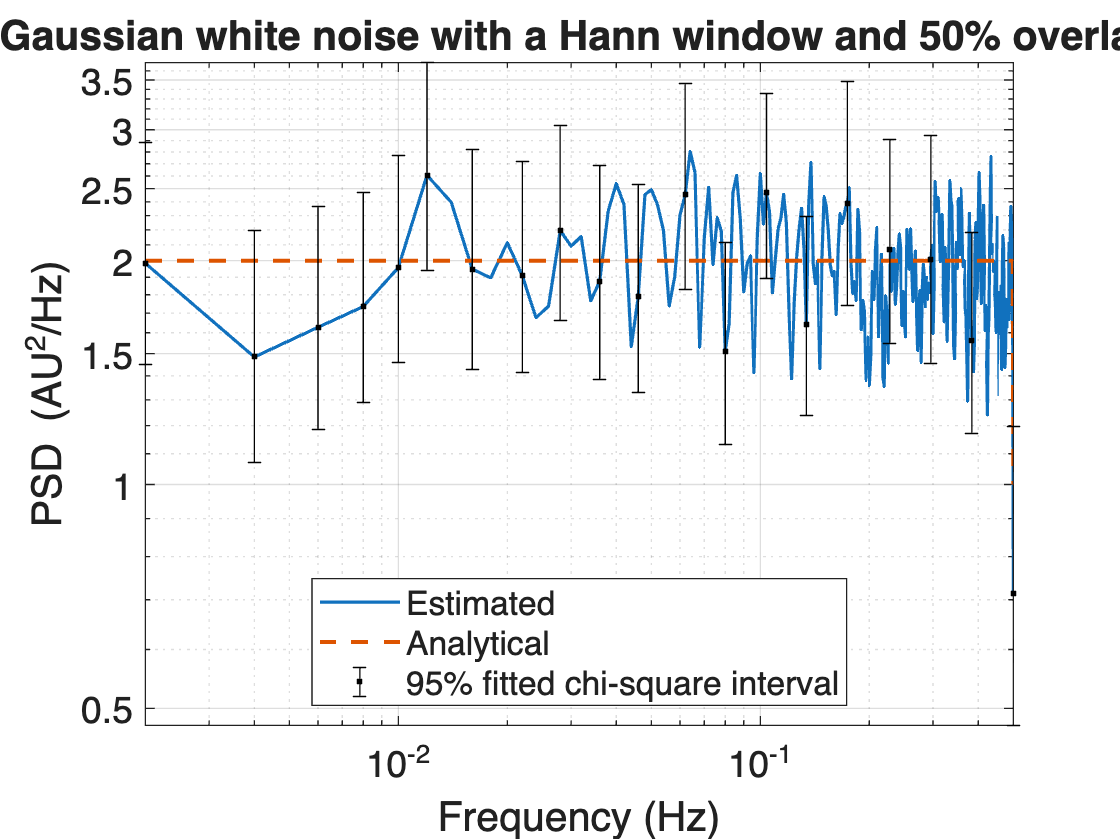

In [38]:
%% 5. Monte Carlo process for a Hann (Hanning) window

window5 = 0.5 - 0.5*cos(2*pi*(0:L-1)'/L);
windowPower5 = sum(window5.^2);
ensembleCount5 = 200;
stream5 = RandStream('mt19937ar', 'Seed', 5);
simPSD5 = zeros(numel(f), ensembleCount5);

for record5 = 0:ensembleCount5
    if record5 == 0
        whiteRecord5 = x;
    else
        whiteRecord5 = sqrt(noiseVariance) * randn(stream5, N, 1);
    end
    fft5 = fft(whiteRecord5(indices) .* window5, [], 1);
    segmentPSD5 = (dt/windowPower5) * abs(fft5(1:numel(f), :)).^2;
    segmentPSD5(2:end-1, :) = 2 * segmentPSD5(2:end-1, :);
    averagedPSD5 = mean(segmentPSD5, 2);
    if record5 == 0
        observedPSD5 = averagedPSD5;
    else
        simPSD5(:, record5) = averagedPSD5;
    end
end

samples5 = simPSD5(positive, :);
fitDOF5 = 2 * mean(samples5, 2).^2 ./ var(samples5, 0, 2);
segmentCount5 = size(indices, 2);
hop5 = L/2;
windowOverlap5 = sum(window5(1:hop5) .* window5(hop5+1:end)) / windowPower5;
theoryDOF5 = (2 * segmentCount5 / ...
    (1 + 2 * (1 - 1/segmentCount5) * windowOverlap5^2)) * ones(nnz(positive), 1);
theoryDOF5(end) = theoryDOF5(end)/2;

estimate5 = observedPSD5(positive);
lower5 = fitDOF5 .* estimate5 ./ (2*gammaincinv(0.975, fitDOF5/2));
upper5 = fitDOF5 .* estimate5 ./ (2*gammaincinv(0.025, fitDOF5/2));

sorted5 = sort(samples5, 2);
empiricalRatio5 = sorted5(:, 195) ./ sorted5(:, 6);
fitRatio5 = gammaincinv(0.975, fitDOF5/2) ./ gammaincinv(0.025, fitDOF5/2);
theoryRatio5 = gammaincinv(0.975, theoryDOF5/2) ./ gammaincinv(0.025, theoryDOF5/2);
interior5 = 1:nnz(positive)-1;
summary5 = array2table([mean(empiricalRatio5(interior5)), ...
    mean(fitRatio5(interior5)), mean(theoryRatio5(interior5)); ...
    empiricalRatio5(end), fitRatio5(end), theoryRatio5(end)], ...
    'VariableNames', {'EmpiricalRatio', 'FittedChiSquareRatio', 'TheoryChiSquareRatio'}, ...
    'RowNames', {'Interior mean', 'Nyquist'});
disp(summary5)

barBins5 = unique(round(logspace(0, log10(nnz(positive)), 22)));
fig5 = figure('Color', 'w');
loglog(fPositive, estimate5, 'LineWidth', 1.2);
hold on
loglog(fPositive, whiteTheory, '--', 'LineWidth', 1.5);
errorbar(fPositive(barBins5), estimate5(barBins5), ...
    estimate5(barBins5)-lower5(barBins5), upper5(barBins5)-estimate5(barBins5), ...
    'k.', 'LineStyle', 'none', 'CapSize', 5);
legend('Estimated', 'Analytical', '95% fitted chi-square interval', 'Location', 'best')
title('Gaussian white noise with a Hann window and 50% overlap')
xlabel('Frequency (Hz)')
ylabel('PSD (AU^2/Hz)')
xlim([df, f(end)])
grid on

In [41]:
%% 6. Monte Carlo process for a cosine window.
% Finally, repeat the Monte Carlo process for a cosine window (cos(πt/T ), 
% where −T /2 < t < T /2).

%% How many effective degrees of freedom do you obtain for 50% overlap.
%                   MonteCarloDOF    OverlapApproximationDOF
%                    _____________    _______________________

%   Interior mean       66.158                65.138         
%   Nyquist            30.199               32.569         

                     EmpiricalRatio    FittedChiSquareRatio    TheoryChiSquareRatio
                     ______________    ____________________    ____________________

    Interior mean        1.9579               1.9935                  1.9979       
    Nyquist              2.8064               2.7881                   2.681       

                     MonteCarloDOF    OverlapApproximationDOF
                     _____________    _______________________

    Interior mean       66.158                65.138         
    Nyquist             30.199                32.569         



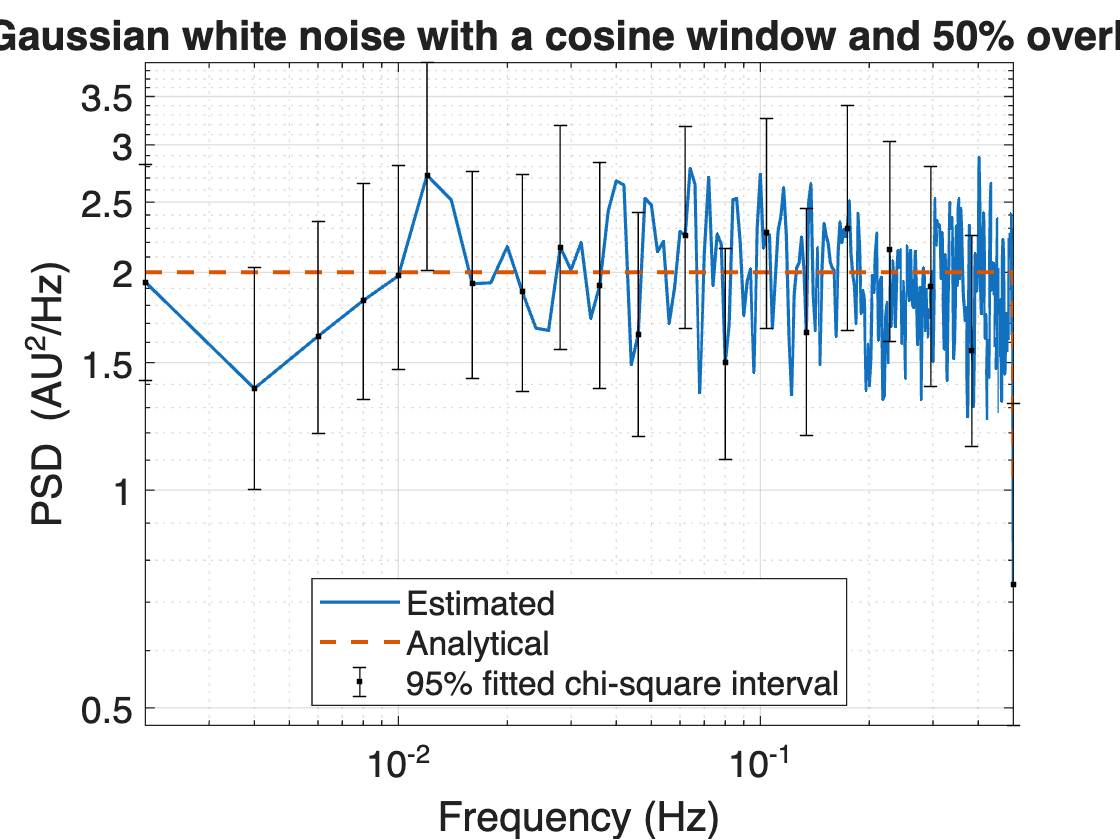

In [42]:
%% 6. Monte Carlo process for a cosine window

T6 = L * dt;
centeredTime6 = ((0:L-1)' + 0.5)*dt - T6/2;
window6 = cos(pi*centeredTime6/T6);
windowPower6 = sum(window6.^2);
ensembleCount6 = 200;
stream6 = RandStream('mt19937ar', 'Seed', 6);
simPSD6 = zeros(numel(f), ensembleCount6);

for record6 = 0:ensembleCount6
    if record6 == 0
        whiteRecord6 = x;
    else
        whiteRecord6 = sqrt(noiseVariance) * randn(stream6, N, 1);
    end
    fft6 = fft(whiteRecord6(indices) .* window6, [], 1);
    segmentPSD6 = (dt/windowPower6) * abs(fft6(1:numel(f), :)).^2;
    segmentPSD6(2:end-1, :) = 2 * segmentPSD6(2:end-1, :);
    averagedPSD6 = mean(segmentPSD6, 2);
    if record6 == 0
        observedPSD6 = averagedPSD6;
    else
        simPSD6(:, record6) = averagedPSD6;
    end
end

samples6 = simPSD6(positive, :);
fitDOF6 = 2 * mean(samples6, 2).^2 ./ var(samples6, 0, 2);
segmentCount6 = size(indices, 2);
hop6 = L/2;
windowOverlap6 = sum(window6(1:hop6) .* window6(hop6+1:end)) / windowPower6;
theoryDOF6 = (2 * segmentCount6 / ...
    (1 + 2 * (1 - 1/segmentCount6) * windowOverlap6^2)) * ones(nnz(positive), 1);
theoryDOF6(end) = theoryDOF6(end)/2;

estimate6 = observedPSD6(positive);
lower6 = fitDOF6 .* estimate6 ./ (2*gammaincinv(0.975, fitDOF6/2));
upper6 = fitDOF6 .* estimate6 ./ (2*gammaincinv(0.025, fitDOF6/2));

% Compare the empirical central 95% range against both chi-square ratios.
sorted6 = sort(samples6, 2);
empiricalRatio6 = sorted6(:, 195) ./ sorted6(:, 6);
fitRatio6 = gammaincinv(0.975, fitDOF6/2) ./ gammaincinv(0.025, fitDOF6/2);
theoryRatio6 = gammaincinv(0.975, theoryDOF6/2) ./ gammaincinv(0.025, theoryDOF6/2);
interior6 = 1:nnz(positive)-1;
summary6 = array2table([mean(empiricalRatio6(interior6)), ...
    mean(fitRatio6(interior6)), mean(theoryRatio6(interior6)); ...
    empiricalRatio6(end), fitRatio6(end), theoryRatio6(end)], ...
    'VariableNames', {'EmpiricalRatio', 'FittedChiSquareRatio', 'TheoryChiSquareRatio'}, ...
    'RowNames', {'Interior mean', 'Nyquist'});
disp(summary6)
dofSummary6 = array2table([mean(fitDOF6(interior6)), theoryDOF6(1); ...
    fitDOF6(end), theoryDOF6(end)], ...
    'VariableNames', {'MonteCarloDOF', 'OverlapApproximationDOF'}, ...
    'RowNames', {'Interior mean', 'Nyquist'});
disp(dofSummary6)

barBins6 = unique(round(logspace(0, log10(nnz(positive)), 22)));
fig6 = figure('Color', 'w');
loglog(fPositive, estimate6, 'LineWidth', 1.2);
hold on
loglog(fPositive, whiteTheory, '--', 'LineWidth', 1.5);
errorbar(fPositive(barBins6), estimate6(barBins6), ...
    estimate6(barBins6)-lower6(barBins6), upper6(barBins6)-estimate6(barBins6), ...
    'k.', 'LineStyle', 'none', 'CapSize', 5);
legend('Estimated', 'Analytical', '95% fitted chi-square interval', 'Location', 'best')
title('Gaussian white noise with a cosine window and 50% overlap')
xlabel('Frequency (Hz)')
ylabel('PSD (AU^2/Hz)')
xlim([df, f(end)])
grid on

In [44]:
%% 7. Bonus. 
% Derive the analytic solution for a cosine window with 50% overlap. 

%% Does it agree with your numerical results?
% Yeah my brain is friend and my cat is begging to cuddle with me. 
% I will be agreeing with my small orange son.
% This homework was by far the hardest. Helpful, but hard. 